In [10]:
import numpy as np
import random
from scipy.linalg import expm as exp
from scipy.linalg import qr, svd
from tqdm import tqdm
import scipy
import math
import matplotlib.pyplot as plt

In [2]:
def H(num):
    H = np.diag(np.ones(num-1),-1)+np.diag(np.ones(num-1),1)
    H[num-1,0]=H[0,num-1]=1

    return H

In [3]:
def initial(num):
    U = np.zeros((num,num//2),dtype=np.complex_)
    for i in range(num//2):
        U[2*i,i]=1+0*1j
    return U, qr(U,mode='economic')[0]

def normalize(U):
    L, N = U.shape
    V=np.empty((L,N),dtype=np.complex_)
    for j in range(N):
        V[:,j]=U[:,j]
        for k in range(j):
            V[:,j]=V[:,j]-np.vdot(U[:,j],V[:,k])*V[:,k]
        V[:,j]=V[:,j]/np.linalg.norm(V[:,j])
    return V 

In [4]:

def generate_gaussian_noise(num_points, num_channels, gamma, dt):
    std_dev = np.sqrt(gamma * dt)
    noise = np.random.normal(loc=0.0, scale=std_dev, size=(num_channels, num_points))
    return noise


In [5]:
def evolution(U_i,H,gamma,dt):
    N = U_i@U_i.conj().T
    nj= np.diag(N).real
    M = np.zeros((U_i.shape[0],U_i.shape[0]), dtype=np.complex_)
    for i in range(U_i.shape[0]):
        M[i,i] = random.gauss(mu =0, sigma= np.sqrt(gamma*dt))+ gamma*(2*nj[i]-1)*dt

    U_tdt =  exp(M)@exp(-1j*H*dt)@U_i
    U_tnorm = normalize(U_tdt)
    
    return qr(U_tdt,mode= 'economic')[0],U_tdt, U_tnorm,nj[0],nj[1]

In [6]:
def evolutionx(U_i,H,gamma,dt):
    N = U_i@U_i.conj().T
    nj= np.diag(N).real
    Noise = np.diag(generate_gaussian_noise(U_i.shape[0], 1, gamma, dt)[0])
    M = np.zeros((U_i.shape[0],U_i.shape[0]), dtype=np.complex_)
    
    for i in range(U_i.shape[0]):
        M[i,i] =  Noise[i,i]+ gamma*(2*nj[i]-1)*dt

    U_tdt =  exp(M)@exp(-1j*H*dt)@U_i
    U_tnorm = normalize(U_tdt)
    
    return qr(U_tdt,mode= 'economic')[0], U_tnorm,nj[0],nj[1]

In [7]:
def entropy(x):
    x= x.real
    eps = 1e-10  # Small value to prevent log2(0)
    
    # Clamp x within [eps, 1 - eps] to avoid log2(0) errors
    if x <= eps or x >= 1 - eps:
        return 0
    
    return -(x*math.log2(x)+ (1-x)*math.log2(1-x))

In [8]:
def sin(x,L):
    return math.sin(math.pi*x/L)

In [101]:
gamma_values = [0.25,2.0,6.0]

N=100
dt = 0.5
time = np.arange(0,N+dt,dt)
traj = 1000
Ham =H(200)




S = []

for t in tqdm(range(traj)):

    U_init,_ = initial(200)
    for t in range(len(time)):     
        U_init,_,_,_,_ = evolution(U_init,Ham,0.25,dt)


    Matrix = (U_init@U_init.conj().T).T
    Mat2 = Matrix[:100,:100]

    alleigval = np.linalg.eig(Mat2)[0]



    
    S.append(np.sum([entropy(x) for x in alleigval]))





100%|██████████| 1000/1000 [1:52:50<00:00,  6.77s/it]


In [102]:
N=100
dt = 0.5
time = np.arange(0,N+dt,dt)
traj = 1000
Ham =H(200)




S2 = []

for t in tqdm(range(traj)):

    U_init,_ = initial(200)
    for t in range(len(time)):     
        U_init,_,_,_,_ = evolution(U_init,Ham,2.0,dt)


    Matrix = (U_init@U_init.conj().T).T
    Mat2 = Matrix[:100,:100]

    alleigval = np.linalg.eig(Mat2)[0]



    
    S2.append(np.sum([entropy(x) for x in alleigval]))

100%|██████████| 1000/1000 [1:57:08<00:00,  7.03s/it]


In [90]:
N=100
dt = 0.5
time = np.arange(0,N+dt,dt)
traj = 1000
Ham =H(200)




S3 = []

for t in tqdm(range(traj)):

    U_init,_ = initial(200)
    for t in range(len(time)):     
        U_init,_,_,_,_ = evolution(U_init,Ham,6.0,dt)


    Matrix = (U_init@U_init.conj().T).T
    Mat2 = Matrix[:100,:100]

    alleigval = np.linalg.eig(Mat2)[0]



    
    S3.append(np.sum([entropy(x) for x in alleigval]))

100%|██████████| 1000/1000 [1:53:11<00:00,  6.79s/it]


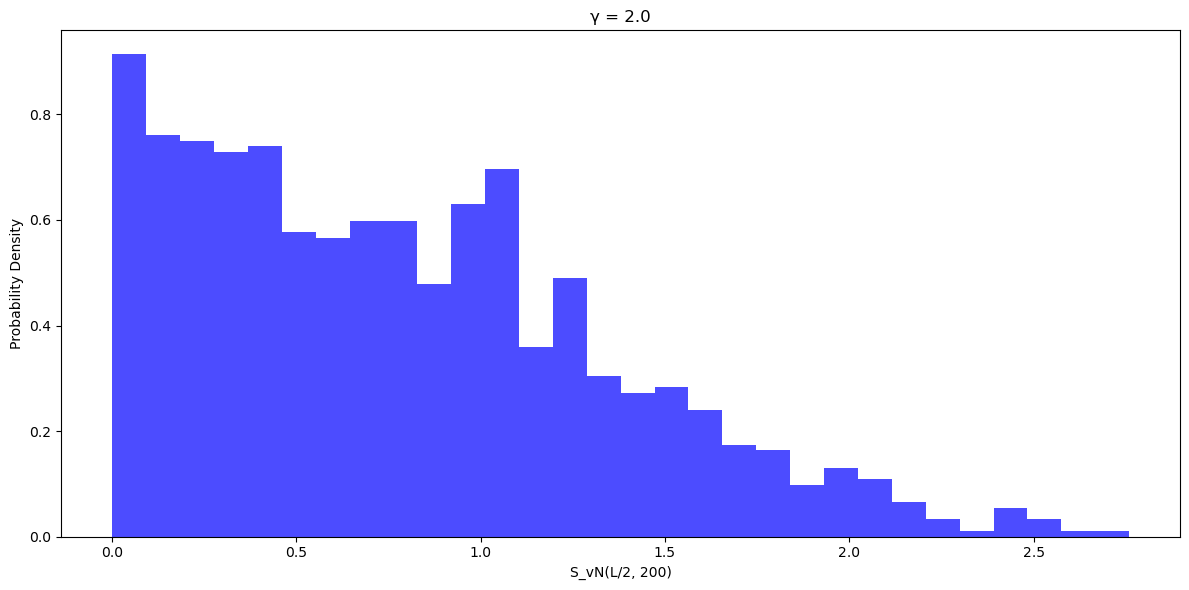

In [123]:
fig, axes = plt.subplots(1, 1, figsize=(12, 6), sharey=True)

axes.hist(S2, bins=30, density=True, color='blue', alpha=0.7)
axes.set_title(f"γ = {2.0}")
axes.set_xlabel("S_vN(L/2, 200)")
axes.set_ylabel("Probability Density")
  


plt.tight_layout()
plt.show()

In [48]:
Mat2.shape

(25, 25)

In [ ]:
TotalS= [S, S2,S3]

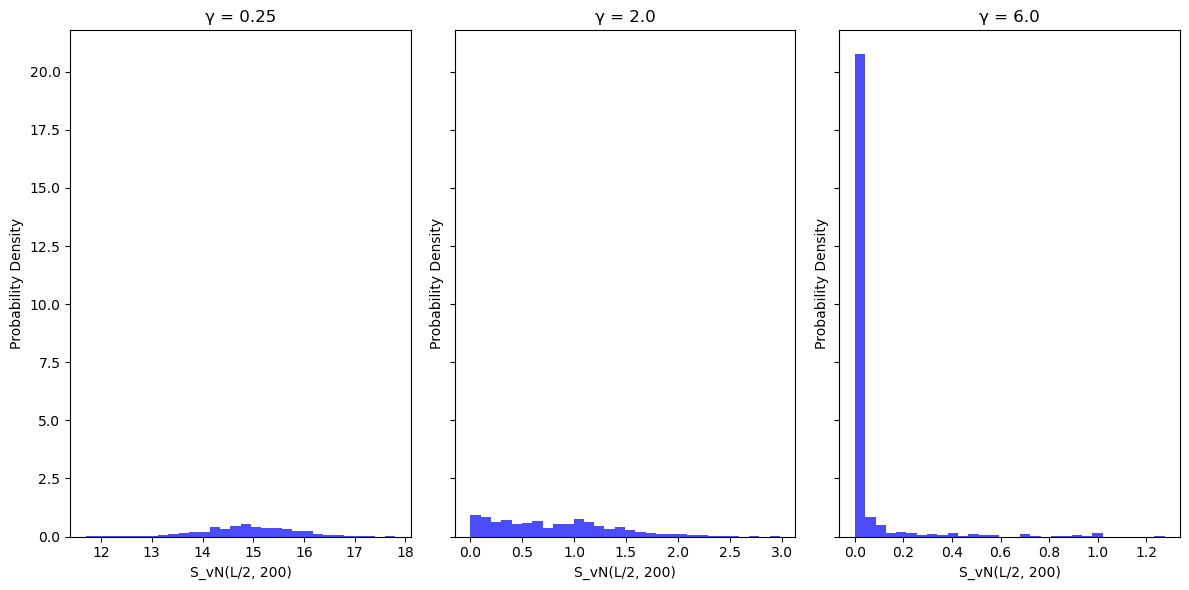

In [127]:
fig, axes = plt.subplots(1, 3, figsize=(12, 6), sharey=True)
for i, gamma in enumerate(gamma_values):
    axes[ i].hist(TotalS[i], bins=30, density=True, color='blue', alpha=0.7)
    axes[i].set_title(f"γ = {gamma}")
    axes[i].set_xlabel("S_vN(L/2, 200)")

    axes[i].set_ylabel("Probability Density")
    


plt.tight_layout()
plt.show()